In [1]:
import pandas as pd
import numpy as np

# Load cleaned dataset
df = pd.read_csv("../dataset/cleaned_sms.csv")

# Display first five records
df.head()

,label,message,message_length
0,ham,"Go until jurong point, crazy.. Available only ...",111
1,ham,Ok lar... Joking wif u oni...,29
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,155
3,ham,U dun say so early hor... U c already then say...,49
4,ham,"Nah I don't think he goes to usf, he lives aro...",61


In [2]:
print("dataset shape: ", df.shape)
print("columns: ", df.columns.tolist())
print("Missing Values: ", df.isnull().sum())

dataset shape:  (5169, 3)
columns:  ['label', 'message', 'message_length']
Missing Values:  label             0
message           0
message_length    0
dtype: int64


In [3]:
df = df[['label','message']].copy()

df['label'] = df['label'].map({
    'ham':0,
    'spam':1
})

print(df.head())

print("Label Distribution: ")
print(df['label'].value_counts())

   label                                            message
0      0  Go until jurong point, crazy.. Available only ...
1      0                      Ok lar... Joking wif u oni...
2      1  Free entry in 2 a wkly comp to win FA Cup fina...
3      0  U dun say so early hor... U c already then say...
4      0  Nah I don't think he goes to usf, he lives aro...
Label Distribution: 
label
0    4516
1     653
Name: count, dtype: int64


In [9]:
import re
import nltk


In [7]:
def preprocess_text(text):

    # Convert to lowercase
    text = text.lower()

    # Replace URLs
    text = re.sub(r'https?://\S+|www\.\S+', ' URL ', text)

    # Replace email addresses
    text = re.sub(r'\S+@\S+', ' EMAIL ', text)

    # Remove unnecessary special characters
    text = re.sub(r'[^a-z0-9\s]', ' ', text)

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text

In [8]:
df['clean_message'] = df['message'].apply(preprocess_text)

# Display original and cleaned messages
df[['message', 'clean_message']].head(10)

,message,clean_message
0,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in 2 a wkly comp to win fa cup fina...
3,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say
4,"Nah I don't think he goes to usf, he lives aro...",nah i don t think he goes to usf he lives arou...
5,FreeMsg Hey there darling it's been 3 week's n...,freemsg hey there darling it s been 3 week s n...
6,Even my brother is not like to speak with me. ...,even my brother is not like to speak with me t...
7,As per your request 'Melle Melle (Oru Minnamin...,as per your request melle melle oru minnaminun...
8,WINNER!! As a valued network customer you have...,winner as a valued network customer you have b...
9,Had your mobile 11 months or more? U R entitle...,had your mobile 11 months or more u r entitled...


In [10]:
for i in range(5):
    print("Original:", df['message'].iloc[i])
    print("Cleaned:", df['clean_message'].iloc[i])
    print("-" * 60)

Original: Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...
Cleaned: go until jurong point crazy available only in bugis n great world la e buffet cine there got amore wat
------------------------------------------------------------
Original: Ok lar... Joking wif u oni...
Cleaned: ok lar joking wif u oni
------------------------------------------------------------
Original: Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
Cleaned: free entry in 2 a wkly comp to win fa cup final tkts 21st may 2005 text fa to 87121 to receive entry question std txt rate t c s apply 08452810075over18 s
------------------------------------------------------------
Original: U dun say so early hor... U c already then say...
Cleaned: u dun say so early hor u c already then say
------------------------------------------------------------
Origin

In [11]:
# Check empty messages
empty_messages = (df['clean_message'].str.strip() == '').sum()

# Check missing values
print("Empty Cleaned Messages:", empty_messages)

print("\nMissing Values:")
print(df[['label', 'clean_message']].isnull().sum())

# Check dataset shape
print("\nDataset Shape:", df.shape)

Empty Cleaned Messages: 2

Missing Values:
label            0
clean_message    0
dtype: int64

Dataset Shape: (5169, 3)


In [13]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.21.0


In [14]:
# Initialize tokenizer
tokenizer = Tokenizer(oov_token="<OOV>")

# Fit tokenizer on cleaned SMS messages
tokenizer.fit_on_texts(df['clean_message'])

# Get vocabulary size
vocab_size = len(tokenizer.word_index) + 1

print("Vocabulary Size:", vocab_size)

Vocabulary Size: 8673


In [15]:
# Convert messages into numerical sequences
sequences = tokenizer.texts_to_sequences(df['clean_message'])

# Display original messages and their sequences
for i in range(5):
    print("Message:", df['clean_message'].iloc[i])
    print("Sequence:", sequences[i])
    print("-" * 60)

Message: go until jurong point crazy available only in bugis n great world la e buffet cine there got amore wat
Sequence: [51, 426, 3925, 761, 696, 652, 71, 9, 1173, 98, 128, 415, 1174, 148, 2635, 1175, 64, 60, 3926, 130]
------------------------------------------------------------
Message: ok lar joking wif u oni
Sequence: [53, 300, 1332, 427, 7, 1729]
------------------------------------------------------------
Message: free entry in 2 a wkly comp to win fa cup final tkts 21st may 2005 text fa to 87121 to receive entry question std txt rate t c s apply 08452810075over18 s
Sequence: [56, 525, 9, 22, 5, 993, 919, 4, 218, 2636, 1176, 697, 2637, 2638, 258, 2639, 74, 2636, 4, 2640, 4, 362, 525, 590, 1177, 87, 428, 24, 124, 18, 429, 3927, 18]
------------------------------------------------------------
Message: u dun say so early hor u c already then say
Sequence: [7, 224, 155, 27, 350, 2641, 7, 124, 147, 61, 155]
------------------------------------------------------------
Message: nah i 

In [16]:
# Calculate sequence lengths
sequence_lengths = [len(seq) for seq in sequences]

# Display statistics
print("Maximum Sequence Length:", max(sequence_lengths))
print("Minimum Sequence Length:", min(sequence_lengths))
print("Average Sequence Length:", np.mean(sequence_lengths))

Maximum Sequence Length: 190
Minimum Sequence Length: 0
Average Sequence Length: 15.928225962468563


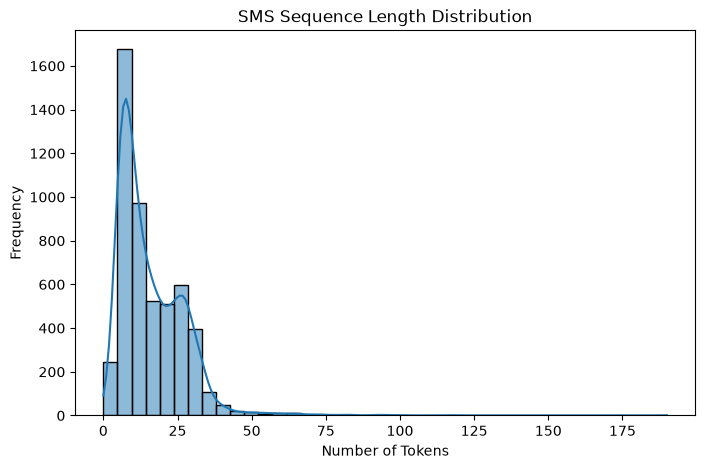

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.histplot(sequence_lengths, bins=40, kde=True)

plt.title("SMS Sequence Length Distribution")
plt.xlabel("Number of Tokens")
plt.ylabel("Frequency")

plt.show()

In [19]:
# Determine maximum sequence length
max_length = int(np.percentile(sequence_lengths, 95))

print("Selected Maximum Length:", max_length)

# Apply padding
padded_sequences = pad_sequences(
    sequences,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

print("Padded Sequences Shape:", padded_sequences.shape)

Selected Maximum Length: 33
Padded Sequences Shape: (5169, 33)


In [20]:
print("Original Sequence:")
print(sequences[0])

print("\nPadded Sequence:")
print(padded_sequences[0])

print("\nFinal Shape:")
print(padded_sequences.shape)

Original Sequence:
[51, 426, 3925, 761, 696, 652, 71, 9, 1173, 98, 128, 415, 1174, 148, 2635, 1175, 64, 60, 3926, 130]

Padded Sequence:
[  51  426 3925  761  696  652   71    9 1173   98  128  415 1174  148
 2635 1175   64   60 3926  130    0    0    0    0    0    0    0    0
    0    0    0    0    0]

Final Shape:
(5169, 33)


In [23]:
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
import numpy as np

In [24]:
X = df['clean_message']
y = df['label']

print("Message: ", X.shape)
print("Label: ", y.shape)

Message:  (5169,)
Label:  (5169,)


In [25]:
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [26]:
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=0.10,
    random_state=42,
    stratify=y_temp
)

In [27]:
print("Training Samples:", len(X_train))
print("Validation Samples:", len(X_val))
print("Testing Samples:", len(X_test))

print("\nTraining Distribution:")
print(y_train.value_counts())

print("\nValidation Distribution:")
print(y_val.value_counts())

print("\nTesting Distribution:")
print(y_test.value_counts())

Training Samples: 3721
Validation Samples: 414
Testing Samples: 1034

Training Distribution:
label
0    3251
1     470
Name: count, dtype: int64

Validation Distribution:
label
0    362
1     52
Name: count, dtype: int64

Testing Distribution:
label
0    903
1    131
Name: count, dtype: int64


In [28]:
tokenizer = Tokenizer(oov_token="<OOV>")

tokenizer.fit_on_texts(X_train)

vocab_size = len(tokenizer.word_index) + 1

print("Vocabulary size: ", vocab_size)

Vocabulary size:  7197


In [29]:
train_sequences = tokenizer.texts_to_sequences(X_train)
val_sequences = tokenizer.texts_to_sequences(X_val)
test_sequences = tokenizer.texts_to_sequences(X_test)

In [30]:
max_length = int(np.percentile(
    [len(seq) for seq in train_sequences], 95
))

X_train_pad = pad_sequences(
    train_sequences,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

X_val_pad = pad_sequences(
    val_sequences,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

X_test_pad = pad_sequences(
    test_sequences,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

In [31]:
print("Training Shape:", X_train_pad.shape)
print("Validation Shape:", X_val_pad.shape)
print("Testing Shape:", X_test_pad.shape)

print("\nVocabulary Size:", vocab_size)
print("Maximum Sequence Length:", max_length)

Training Shape: (3721, 33)
Validation Shape: (414, 33)
Testing Shape: (1034, 33)

Vocabulary Size: 7197
Maximum Sequence Length: 33


In [32]:
from sklearn.model_selection import train_test_split

X = df['clean_message']
y = df['label']

# 80% temporary data, 20% testing
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Split temporary data into training and validation
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=0.10,
    random_state=42,
    stratify=y_temp
)

In [33]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
import numpy as np

tokenizer = Tokenizer(oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

vocab_size = len(tokenizer.word_index) + 1

print("Vocabulary Size:", vocab_size)

Vocabulary Size: 7197


In [34]:
train_sequences = tokenizer.texts_to_sequences(X_train)
val_sequences = tokenizer.texts_to_sequences(X_val)
test_sequences = tokenizer.texts_to_sequences(X_test)

In [35]:
max_length = int(np.percentile(
    [len(seq) for seq in train_sequences], 95
))

X_train_pad = pad_sequences(
    train_sequences,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

X_val_pad = pad_sequences(
    val_sequences,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

X_test_pad = pad_sequences(
    test_sequences,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

In [36]:
print("Training:", X_train_pad.shape)
print("Validation:", X_val_pad.shape)
print("Testing:", X_test_pad.shape)

Training: (3721, 33)
Validation: (414, 33)
Testing: (1034, 33)


In [37]:
import numpy as np
import pickle
import os

# Create models folder if it doesn't exist
os.makedirs("../models", exist_ok=True)

# Save training, validation, and testing data
np.savez_compressed(
    "../models/preprocessed_data.npz",
    X_train=X_train_pad,
    X_val=X_val_pad,
    X_test=X_test_pad,
    y_train=np.array(y_train),
    y_val=np.array(y_val),
    y_test=np.array(y_test)
)

# Save tokenizer
with open("../models/tokenizer.pkl", "wb") as file:
    pickle.dump(tokenizer, file)

print("Preprocessed data saved successfully!")
print("Tokenizer saved successfully!")
print("Files in models folder:", os.listdir("../models"))

Preprocessed data saved successfully!
Tokenizer saved successfully!
Files in models folder: ['preprocessed_data.npz', 'tokenizer.pkl']
